## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 16.08.2024

Date of Last Modification: 17.08.2024

# 1. Setup

## 1.1 Libraries 

In [60]:
import torch
import os
import logging
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
from src.nichejepa.train import train
from src.nichejepa.eval import evaluation
from src.nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from src.nichejepa.utils.distributed import init_distributed
from src.nichejepa.utils.eval_utils import clustering_metrics, classification_metrics
import numpy as np


## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [2]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('configs/merfish.yaml',logger)

INFO:root:Loaded parameters from YAML file.


## 1.3 Create Train,Test dataset

In [3]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Loading dataset from disk:   0%|          | 0/52 [00:00<?, ?it/s]

Dataset({
    features: ['gene_tokens_cell', 'gene_tokens_neighborhood', 'cell_types', 'niche_types', 'donor_id', 'sample_id', 'batch_id', 'input_ids'],
    num_rows: 80000
})

## 1.4 INIT distributed (it should change later)

In [4]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40316)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2.Model Training With just_cell and just_neighborhood as True

## 2.1 Train Model

In [6]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:[1,     0] loss: 0.520 masks: 305.0 20.0 [wd: 4.00e-02] [lr: 5.00e-05] [mem: 1.06e+04] (417.8 ms)
INFO:root:[1,     0] grad_stats: [8.17e-02 7.17e-02] (2.72e-04, 9.38e-02)
INFO:root:[1,    10] loss: 0.361 masks: 300.5 19.9 [wd: 4.00e-02] [lr: 4.95e-05] [mem: 1.10e+04] (248.5 ms)
INFO:root:[1,    10] grad_stats: [3.60e-03 3.91e-03] (1.39e-05, 4.58e-03)
INFO:root:[1,    20] loss: 0.332 masks: 301.1 19.9 [wd: 4.00e-02] [lr: 4.90e-05] [mem: 1.10e+04] (240.9 ms)
INFO:root:[1,    20] grad_stats: [1.99e-03 2.06e-03] (7.46e-06, 2.56e-03)
INFO:root:[1,    30] loss: 0.320 masks: 299.8 19.9 [wd: 4.01e-02] [lr: 4.85e-05] [mem: 1.10e+04] (237.0 ms)
INFO:root:[1,    30] grad_stats: [7.29e-04 7.39e-04] (3.61e-06, 8.70e-04)
INFO:root:[1,    40] loss: 0.314 masks: 299.3 19.9 [wd: 4.02e-02] [lr: 4.80e-05] [mem: 1.10e+04] (234.7 ms)
INFO:root:[1,    40] grad_stats: [1.53e-03 1.68e-03] (5.86e-06, 2.07e-03)
INFO:root:[1,    50] loss: 0.307 masks: 300.4 19.9 [wd: 4.03e-02] [lr: 4.75e-05] [mem: 1.1

# 3. Analysis With just_cell and just_neighborhood as True

## 3.1 Cell Type Average

In [11]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.65it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.43it/s]
100it [00:33,  2.96it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total/extracted_features/cell_embedding_average.h5ad


### 3.1.1 Feature Analysis

In [69]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total//extracted_features/cell_embedding_average.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.99999976 0.9949485  0.9938998  ... 0.9943806  0.9950819  0.99520206]
 [0.9949485  1.0000001  0.99473107 ... 0.9968875  0.99718344 0.9972013 ]
 [0.9938998  0.99473107 1.         ... 0.995008   0.99525225 0.9949209 ]
 ...
 [0.9943806  0.9968875  0.995008   ... 1.0000005  0.9975172  0.9979484 ]
 [0.9950819  0.99718344 0.99525225 ... 0.9975172  0.9999999  0.99753165]
 [0.99520206 0.9972013  0.9949209  ... 0.9979484  0.99753165 0.99999994]]


array([[ 1.4253829 ,  0.4436868 ,  1.1808329 , ...,  0.22650018,
         0.06807875, -1.2705333 ],
       [ 1.3674368 ,  0.40766615,  1.1166619 , ...,  0.22724555,
         0.12982114, -1.2655499 ],
       [ 1.4021033 ,  0.52104616,  1.178243  , ...,  0.20506804,
         0.09566615, -1.2491161 ],
       ...,
       [ 1.340192  ,  0.50193495,  1.2066104 , ...,  0.27882063,
         0.12178081, -1.2941773 ],
       [ 1.4176451 ,  0.42561546,  1.117481  , ...,  0.28651482,
         0.15198264, -1.2788447 ],
       [ 1.4062928 ,  0.38327044,  1.2291795 , ...,  0.26313165,
         0.1767314 , -1.2235262 ]], dtype=float32)

### 3.1.2 Umap

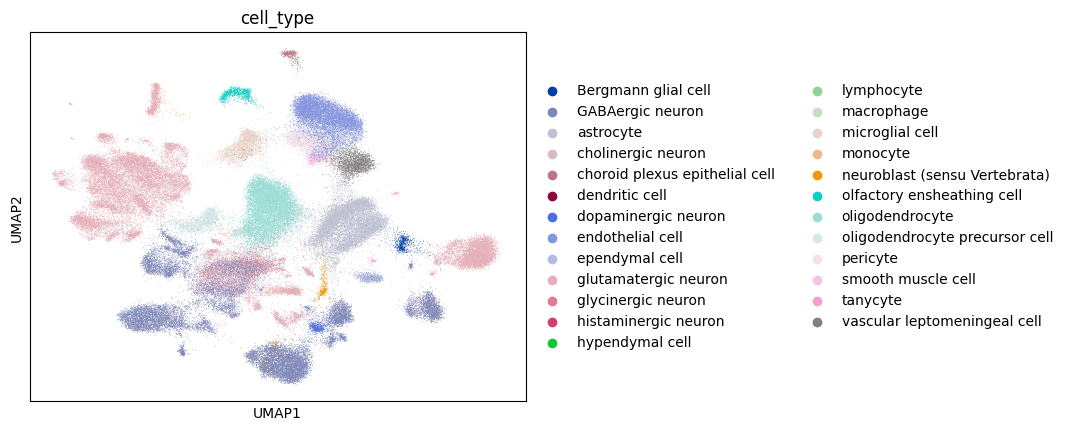

In [13]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.1.3 Logistic regression

In [14]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.88
Test F1 Score: 0.86
Train Accuracy: 0.88
Train F1 Score: 0.86


{'test_accuracy': 0.88385,
 'test_f1': 0.8639659732680377,
 'train_accuracy': 0.8831,
 'train_f1': 0.8637948928185939}

### 3.1.4 KNeighborsClassifier

In [15]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.92
Test F1 Score: 0.92
Train Accuracy: 0.94
Train F1 Score: 0.94


{'test_accuracy': 0.9187,
 'test_f1': 0.9150091278721593,
 'train_accuracy': 0.93915,
 'train_f1': 0.9367876686912432}

### 3.1.5 nmi&ari

In [16]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.5410345093973511
ARI (Adjusted Rand Index): 0.23781270002232616


{'nmi': 0.5410345093973511, 'ari': 0.23781270002232616}

## 3.2 Cell Type CLS

In [17]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.65it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:57,  3.41it/s]
100it [00:34,  2.92it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total/extracted_features/cell_embedding_cls.h5ad


### 3.2.1 Feature Analysis

In [70]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total//extracted_features/cell_embedding_cls.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000002  0.9998718  0.99993455 ... 0.99976367 0.9997232  0.9997829 ]
 [0.9998718  0.99999976 0.99996495 ... 0.99996614 0.99995434 0.9999701 ]
 [0.99993455 0.99996495 1.0000002  ... 0.9999181  0.99989235 0.9999254 ]
 ...
 [0.99976367 0.99996614 0.9999181  ... 1.         0.99998116 0.9999868 ]
 [0.9997232  0.99995434 0.99989235 ... 0.99998116 1.0000001  0.9999791 ]
 [0.9997829  0.9999701  0.9999254  ... 0.9999868  0.9999791  1.        ]]


array([[ 2.2549868 ,  0.07496642,  2.0519764 , ...,  0.22446759,
         0.12751877, -2.397234  ],
       [ 2.2653196 ,  0.05704219,  2.061022  , ...,  0.21497497,
         0.14722738, -2.4137197 ],
       [ 2.2683392 ,  0.06033234,  2.0622485 , ...,  0.22545134,
         0.14128393, -2.4079044 ],
       ...,
       [ 2.2585168 ,  0.064248  ,  2.0499642 , ...,  0.21985504,
         0.12514141, -2.3974836 ],
       [ 2.2821496 ,  0.04478808,  2.0605295 , ...,  0.21621966,
         0.15436123, -2.4216607 ],
       [ 2.2591164 ,  0.07568581,  2.0576131 , ...,  0.21963309,
         0.13424169, -2.409281  ]], dtype=float32)

### 3.2.2 Umap

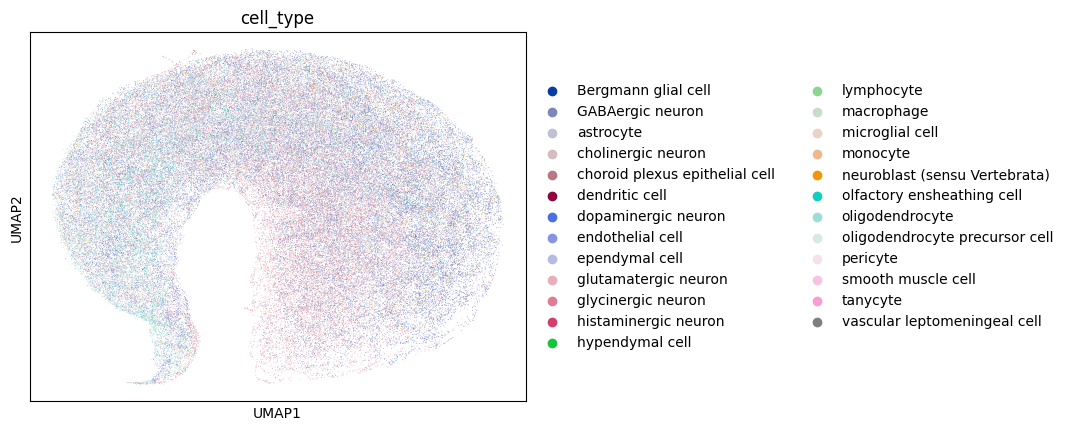

In [19]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [20]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.34
Test F1 Score: 0.22
Train Accuracy: 0.33
Train F1 Score: 0.21


{'test_accuracy': 0.33895,
 'test_f1': 0.21871996166709942,
 'train_accuracy': 0.33315,
 'train_f1': 0.21466015861055734}

### 3.2.4 KNeighborsClassifier

In [21]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.79
Test F1 Score: 0.77
Train Accuracy: 0.85
Train F1 Score: 0.84


{'test_accuracy': 0.78815,
 'test_f1': 0.7743785773858858,
 'train_accuracy': 0.853225,
 'train_f1': 0.8448039940516848}

### 3.2.5 nmi&ari

In [22]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.046156955843258324
ARI (Adjusted Rand Index): 0.007887589085681513


{'nmi': 0.046156955843258324, 'ari': 0.007887589085681513}

## 3.3 Cell Type weighted_average

In [29]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.65it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:57,  3.42it/s]
100it [00:33,  2.96it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total/extracted_features/cell_embedding_weighted_average.h5ad


### 3.3.1 Feature Analysis

In [71]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total//extracted_features/cell_embedding_weighted_average.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000001  0.9930432  0.99742603 ... 0.99390686 0.99137807 0.99408066]
 [0.9930432  1.0000002  0.98781985 ... 0.9984751  0.99866927 0.99868727]
 [0.99742603 0.98781985 0.9999995  ... 0.9896418  0.98577935 0.9895028 ]
 ...
 [0.99390686 0.9984751  0.9896418  ... 0.99999994 0.9984685  0.99919116]
 [0.99137807 0.99866927 0.98577935 ... 0.9984685  1.0000002  0.998557  ]
 [0.99408066 0.99868727 0.9895028  ... 0.99919116 0.998557   0.99999976]]


array([[ 0.8556363 ,  0.89485157,  0.75209504, ...,  0.01838087,
        -0.5983519 , -1.2936815 ],
       [ 0.89461344,  0.82188314,  0.774747  , ...,  0.00241436,
        -0.46616933, -1.2726685 ],
       [ 0.77182096,  0.9564647 ,  0.7346147 , ..., -0.03965461,
        -0.6393484 , -1.2723693 ],
       ...,
       [ 0.93372595,  0.8192129 ,  0.88278186, ...,  0.0824023 ,
        -0.38576764, -1.3243864 ],
       [ 0.8344215 ,  0.84884226,  0.7480203 , ..., -0.00609299,
        -0.52892375, -1.2890296 ],
       [ 0.97116905,  0.75531095,  0.8914458 , ...,  0.05846098,
        -0.34186238, -1.2639415 ]], dtype=float32)

### 3.3.2 Umap

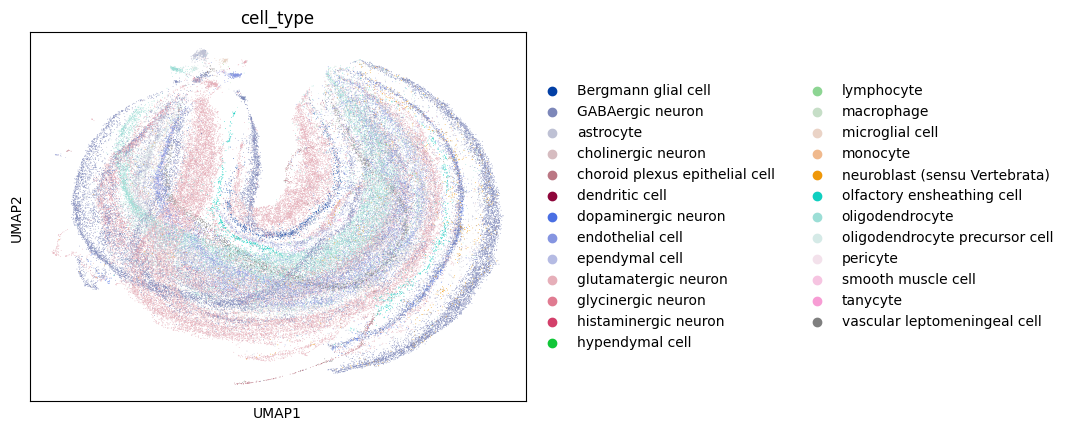

In [31]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [32]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.76
Test F1 Score: 0.72
Train Accuracy: 0.76
Train F1 Score: 0.72


{'test_accuracy': 0.7595,
 'test_f1': 0.7175161371968363,
 'train_accuracy': 0.7578,
 'train_f1': 0.7163118521495132}

### 3.3.4 KNN

In [33]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.85
Test F1 Score: 0.84
Train Accuracy: 0.89
Train F1 Score: 0.88


{'test_accuracy': 0.8453,
 'test_f1': 0.8391845480466412,
 'train_accuracy': 0.8884875,
 'train_f1': 0.8844682153636699}

### 3.3.5 nmi&ari

In [34]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.06129517290316353
ARI (Adjusted Rand Index): 0.020931970138085194


{'nmi': 0.06129517290316353, 'ari': 0.020931970138085194}

## 3.4 Niche Type Average

In [5]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>


400it [04:56,  1.35it/s]
100it [01:01,  1.63it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total/extracted_features/niche_embedding_average.h5ad


### 3.4.1 Feature Analysis

In [72]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total//extracted_features/niche_embedding_average.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.9999998  0.9990875  0.99912083 ... 0.99899936 0.9988812  0.99899524]
 [0.9990875  0.99999976 0.9993254  ... 0.9994377  0.99947774 0.99949455]
 [0.99912083 0.9993254  0.99999994 ... 0.9993597  0.9992934  0.9993465 ]
 ...
 [0.99899936 0.9994377  0.9993597  ... 0.9999997  0.9995067  0.99959654]
 [0.9988812  0.99947774 0.9992934  ... 0.9995067  1.         0.999563  ]
 [0.99899524 0.99949455 0.9993465  ... 0.99959654 0.999563   1.        ]]


array([[ 0.6057181 ,  1.0928943 ,  0.5795788 , ..., -0.03571289,
        -0.8429129 , -1.2871803 ],
       [ 0.57949203,  1.087846  ,  0.5493867 , ..., -0.10598878,
        -0.84540117, -1.2660942 ],
       [ 0.59397143,  1.0962248 ,  0.58209825, ..., -0.11551066,
        -0.8739872 , -1.2858756 ],
       ...,
       [ 0.5890169 ,  1.0890561 ,  0.58430743, ..., -0.09343459,
        -0.8245729 , -1.3384547 ],
       [ 0.5847219 ,  1.0569377 ,  0.56088454, ..., -0.11582599,
        -0.83066523, -1.295665  ],
       [ 0.5942453 ,  1.1063634 ,  0.55568266, ..., -0.11105762,
        -0.8218705 , -1.3012072 ]], dtype=float32)

### 3.4.2 Umap

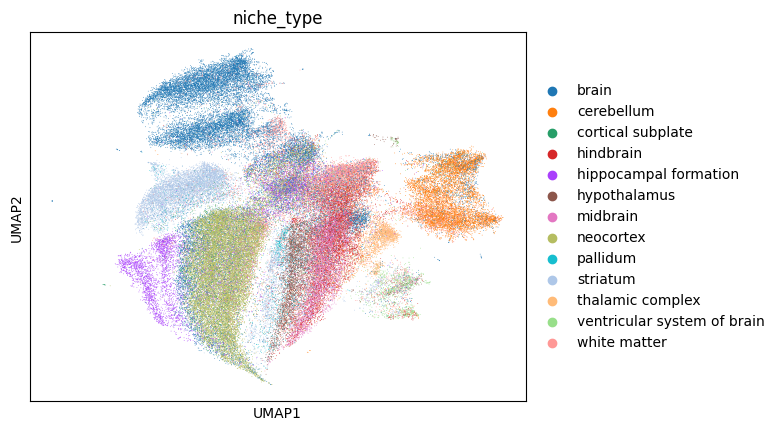

In [9]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [7]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.67
Test F1 Score: 0.65
Train Accuracy: 0.67
Train F1 Score: 0.65


{'test_accuracy': 0.66975,
 'test_f1': 0.6468851034868381,
 'train_accuracy': 0.6709,
 'train_f1': 0.6472152826027519}

### 3.4.4 KNN

In [8]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.76
Test F1 Score: 0.76
Train Accuracy: 0.85
Train F1 Score: 0.84


{'test_accuracy': 0.7609,
 'test_f1': 0.7552102499378517,
 'train_accuracy': 0.84655,
 'train_f1': 0.8437805180989926}

### 3.4.5 nmi&ari

In [10]:
clustering_metrics(adata,label_col='niche_type')

INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
NMI (Normalized Mutual Information): 0.1769110884654026
ARI (Adjusted Rand Index): 0.07930467947417126


{'nmi': 0.1769110884654026, 'ari': 0.07930467947417126}

## 3.5 Niche Type CLS

In [23]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.64it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.43it/s]
100it [00:33,  2.98it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total/extracted_features/niche_embedding_cls.h5ad


### 3.5.1 Feature Analysis

In [73]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total//extracted_features/niche_embedding_cls.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000002  0.9998718  0.99993455 ... 0.99976367 0.9997232  0.9997829 ]
 [0.9998718  0.99999976 0.99996495 ... 0.99996614 0.99995434 0.9999701 ]
 [0.99993455 0.99996495 1.0000002  ... 0.9999181  0.99989235 0.9999254 ]
 ...
 [0.99976367 0.99996614 0.9999181  ... 1.         0.99998116 0.9999868 ]
 [0.9997232  0.99995434 0.99989235 ... 0.99998116 1.0000001  0.9999791 ]
 [0.9997829  0.9999701  0.9999254  ... 0.9999868  0.9999791  1.        ]]


array([[ 2.2549868 ,  0.07496642,  2.0519764 , ...,  0.22446759,
         0.12751877, -2.397234  ],
       [ 2.2653196 ,  0.05704219,  2.061022  , ...,  0.21497497,
         0.14722738, -2.4137197 ],
       [ 2.2683392 ,  0.06033234,  2.0622485 , ...,  0.22545134,
         0.14128393, -2.4079044 ],
       ...,
       [ 2.2585168 ,  0.064248  ,  2.0499642 , ...,  0.21985504,
         0.12514141, -2.3974836 ],
       [ 2.2821496 ,  0.04478808,  2.0605295 , ...,  0.21621966,
         0.15436123, -2.4216607 ],
       [ 2.2591164 ,  0.07568581,  2.0576131 , ...,  0.21963309,
         0.13424169, -2.409281  ]], dtype=float32)

### 3.5.2 Umap

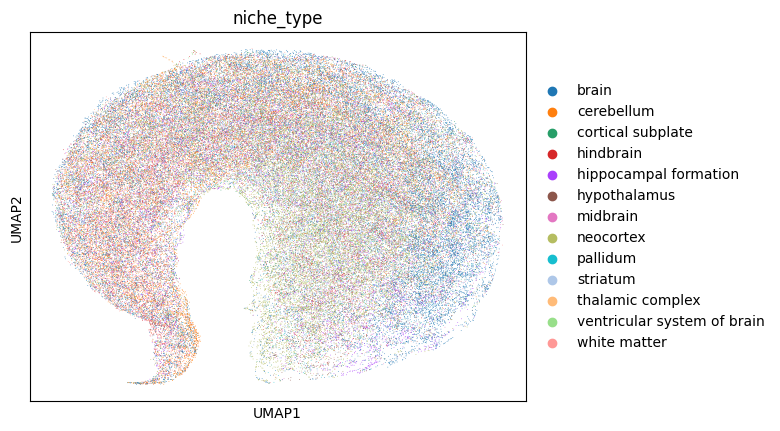

In [25]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [26]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.30
Test F1 Score: 0.19
Train Accuracy: 0.30
Train F1 Score: 0.19


{'test_accuracy': 0.29795,
 'test_f1': 0.19355743550027832,
 'train_accuracy': 0.2986875,
 'train_f1': 0.1935951411604476}

### 3.5.4 KNN

In [27]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.62
Test F1 Score: 0.61
Train Accuracy: 0.75
Train F1 Score: 0.74


{'test_accuracy': 0.625,
 'test_f1': 0.6128302737212357,
 'train_accuracy': 0.7467375,
 'train_f1': 0.7398809541996307}

### 3.5.5 nmi&ari

In [28]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.04308135397679918
ARI (Adjusted Rand Index): 0.01655860658258653


{'nmi': 0.04308135397679918, 'ari': 0.01655860658258653}

## 3.6 Niche Type weighted_average

In [35]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['context_mask_size'] = 361
params['mask']['target_mask_size'] = 19
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 4

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 37

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 37 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:55,  3.66it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:56,  3.44it/s]
100it [00:34,  2.94it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total/extracted_features/niche_embedding_weighted_average.h5ad


### 3.6.1 Feature Analysis

In [74]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_37_just_cell_just_neighborhood_total//extracted_features/niche_embedding_weighted_average.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000001  0.9930432  0.99742603 ... 0.99390686 0.99137807 0.99408066]
 [0.9930432  1.0000002  0.98781985 ... 0.9984751  0.99866927 0.99868727]
 [0.99742603 0.98781985 0.9999995  ... 0.9896418  0.98577935 0.9895028 ]
 ...
 [0.99390686 0.9984751  0.9896418  ... 0.99999994 0.9984685  0.99919116]
 [0.99137807 0.99866927 0.98577935 ... 0.9984685  1.0000002  0.998557  ]
 [0.99408066 0.99868727 0.9895028  ... 0.99919116 0.998557   0.99999976]]


array([[ 0.8556363 ,  0.89485157,  0.75209504, ...,  0.01838087,
        -0.5983519 , -1.2936815 ],
       [ 0.89461344,  0.82188314,  0.774747  , ...,  0.00241436,
        -0.46616933, -1.2726685 ],
       [ 0.77182096,  0.9564647 ,  0.7346147 , ..., -0.03965461,
        -0.6393484 , -1.2723693 ],
       ...,
       [ 0.93372595,  0.8192129 ,  0.88278186, ...,  0.0824023 ,
        -0.38576764, -1.3243864 ],
       [ 0.8344215 ,  0.84884226,  0.7480203 , ..., -0.00609299,
        -0.52892375, -1.2890296 ],
       [ 0.97116905,  0.75531095,  0.8914458 , ...,  0.05846098,
        -0.34186238, -1.2639415 ]], dtype=float32)

### 3.6.2 Umap

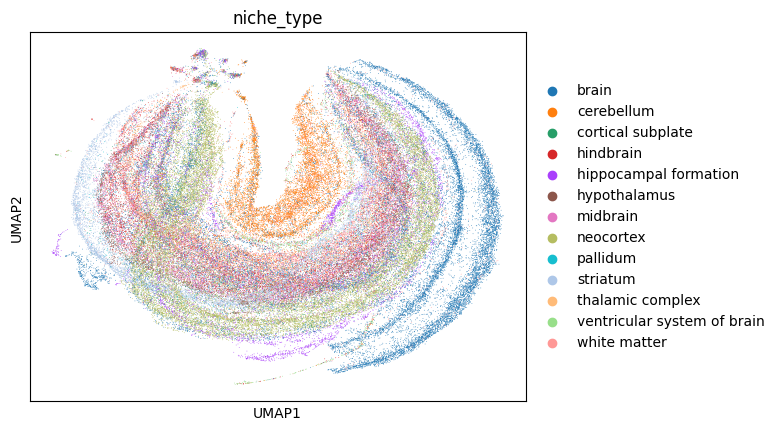

In [37]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [38]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.65
Test F1 Score: 0.63
Train Accuracy: 0.65
Train F1 Score: 0.63


{'test_accuracy': 0.6509,
 'test_f1': 0.6272667954819291,
 'train_accuracy': 0.650725,
 'train_f1': 0.6260758691200072}

### 3.6.4 KNN

In [39]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.71
Test F1 Score: 0.70
Train Accuracy: 0.79
Train F1 Score: 0.79


{'test_accuracy': 0.7061,
 'test_f1': 0.6985244690971066,
 'train_accuracy': 0.7937375,
 'train_f1': 0.7888401327539378}

### 3.6.5 nmi&ari

In [40]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.01996225589490654
ARI (Adjusted Rand Index): 0.0108614040275639


{'nmi': 0.01996225589490654, 'ari': 0.0108614040275639}

# 4.Model Training With just_cell as True

## 4.1 Train Model

In [77]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False

params['mask']['context_mask_size'] = False
params['data']['just_neighborhood'] = False
params['data']['just_neighborhood'] = False
params['data']['just_neighborhood'] = False

params['mask']['context_mask_size'] = 457
params['mask']['target_mask_size'] = 10
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 40
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:[1,     0] loss: 0.517 masks: 285.0 20.0 [wd: 4.00e-02] [lr: 5.00e-05] [mem: 1.17e+04] (164.2 ms)
INFO:root:[1,     0] grad_stats: [1.62e-01 1.34e-01] (3.43e-04, 1.89e-01)
INFO:root:[1,    10] loss: 0.322 masks: 285.0 19.5 [wd: 4.00e-02] [lr: 4.95e-05] [mem: 1.17e+04] (129.7 ms)
INFO:root:[1,    10] grad_stats: [5.27e-03 4.88e-03] (1.18e-05, 6.23e-03)
INFO:root:[1,    20] loss: 0.280 masks: 285.0 19.5 [wd: 4.00e-02] [lr: 4.90e-05] [mem: 1.17e+04] (127.8 ms)
INFO:root:[1,    20] grad_stats: [1.57e-03 1.57e-03] (3.84e-06, 1.98e-03)
INFO:root:[1,    30] loss: 0.260 masks: 285.0 19.5 [wd: 4.01e-02] [lr: 4.85e-05] [mem: 1.17e+04] (127.3 ms)
INFO:root:[1,    30] grad_stats: [6.57e-04 6.80e-04] (1.89e-06, 8.09e-04)
INFO:root:[1,    40] loss: 0.249 masks: 285.0 19.6 [wd: 4.02e-02] [lr: 4.80e-05] [mem: 1.17e+04] (127.2 ms)
INFO:root:[1,    40] grad_stats: [4.80e-04 4.95e-04] (1.56e-06, 6.09e-04)
INFO:root:[1,    50] loss: 0.242 masks: 285.0 19.6 [wd: 4.03e-02] [lr: 4.75e-05] [mem: 1.1

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:avg. loss 0.214
INFO:root:Epoch 2
INFO:root:[2,     0] loss: 0.195 masks: 285.0 20.0 [wd: 4.40e-02] [lr: 4.02e-05] [mem: 1.17e+04] (150.6 ms)
INFO:root:[2,     0] grad_stats: [5.06e-04 5.40e-04] (1.60e-06, 6.50e-04)
INFO:root:[2,    10] loss: 0.194 masks: 285.0 19.4 [wd: 4.44e-02] [lr: 3.97e-05] [mem: 1.17e+04] (127.9 ms)
INFO:root:[2,    10] grad_stats: [5.12e-04 4.96e-04] (1.60e-06, 6.34e-04)
INFO:root:[2,    20] loss: 0.194 masks: 285.0 19.5 [wd: 4.48e-02] [lr: 3.92e-05] [mem: 1.17e+04] (127.7 ms)
INFO:root:[2,    20] grad_stats: [4.94e-04 4.83e-04] (1.58e-06, 6.06e-04)
INFO:root:[2,    30] loss: 0.194 masks: 285.0 19.6 [wd: 4.52e-02] [lr: 3.87e-05] [mem: 1.17e+04] (127.7 ms)
INFO:root:[2,    30] grad_stats: [4.36e-04 4.69e-04] (1.49e-06, 5.70e-04)
INFO:root:[2,    40] loss: 0.193 masks: 285.0 19.6 [wd: 4.57e-02] [lr: 3.82e-05] [mem: 1.17e+04] (127.3 ms)
INFO:root:[2,    40] grad_stats: [4.67e-04 4.68e-04] (1.56e-06, 6.16e-04)
INFO:root:[2,    50] loss: 0.193 masks: 285.0 

# 5. Analysis With just_cell as True

## 5.1 Cell Type Average

In [42]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False

params['mask']['context_mask_size'] = False
params['data']['just_neighborhood'] = False
params['data']['just_neighborhood'] = False
params['data']['just_neighborhood'] = False

params['mask']['context_mask_size'] = 457
params['mask']['target_mask_size'] = 10
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 40
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:04, 16.60it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:04,  6.18it/s]
100it [00:17,  5.72it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_457_num_epochs_40_just_cell_total/extracted_features/cell_embedding_average.h5ad


### 5.1.1 Feature Analysis

In [66]:
#similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_457_num_epochs_40_just_cell_total/extracted_features/cell_embedding_average.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']


[[0.9999999  0.97952473 0.9866342  ... 0.9444407  0.9756093  0.9675443 ]
 [0.97952473 1.0000001  0.98544    ... 0.9706253  0.99271685 0.98741746]
 [0.9866342  0.98544    0.99999976 ... 0.9527445  0.9826545  0.97400904]
 ...
 [0.9444407  0.9706253  0.9527445  ... 1.0000002  0.98123527 0.9891249 ]
 [0.9756093  0.99271685 0.9826545  ... 0.98123527 1.0000002  0.99335206]
 [0.9675443  0.98741746 0.97400904 ... 0.9891249  0.99335206 0.9999999 ]]


array([[ 0.42510805,  0.1402044 ,  1.2779535 , ...,  0.1868914 ,
         0.12264411, -0.7842245 ],
       [ 0.5565899 , -0.04349777,  1.1670066 , ...,  0.24990013,
         0.3079757 , -0.7282809 ],
       [ 0.50837827,  0.19229461,  1.3063436 , ...,  0.1931475 ,
         0.14101069, -0.690527  ],
       ...,
       [ 0.4555619 ,  0.11233008,  1.3289611 , ...,  0.3036404 ,
         0.1666513 , -0.80966777],
       [ 0.5517606 ,  0.04848583,  1.124491  , ...,  0.32219556,
         0.20878087, -0.77337116],
       [ 0.2609772 ,  0.08582038,  1.3318051 , ...,  0.15067583,
         0.11689099, -0.82054037]], dtype=float32)

### 5.1.2 Umap

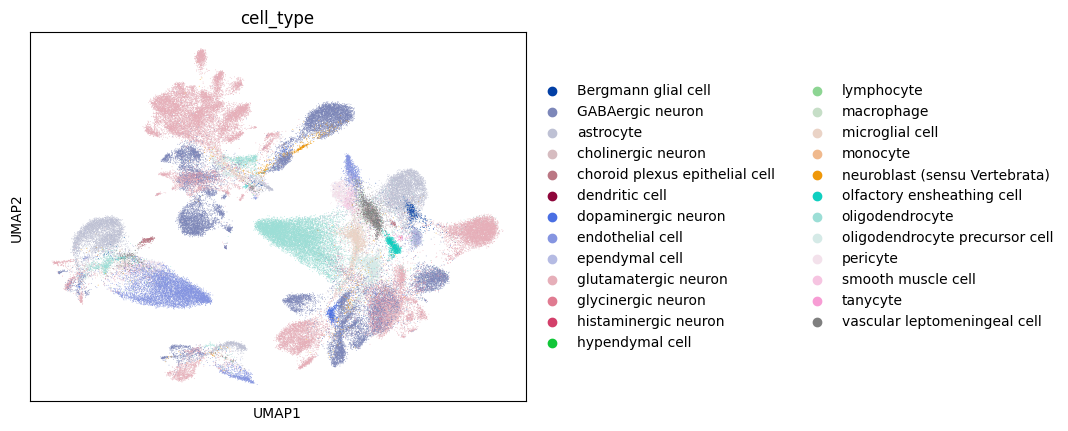

In [44]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.1.3 Logistic regression

In [45]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.90
Test F1 Score: 0.89
Train Accuracy: 0.90
Train F1 Score: 0.88


{'test_accuracy': 0.89755,
 'test_f1': 0.8853456206282071,
 'train_accuracy': 0.8963,
 'train_f1': 0.8847671033821797}

### 5.1.4 KNN

In [46]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.91
Test F1 Score: 0.91
Train Accuracy: 0.93
Train F1 Score: 0.93


{'test_accuracy': 0.91135,
 'test_f1': 0.9080713803860943,
 'train_accuracy': 0.9344,
 'train_f1': 0.9324122651243583}

### 5.1.5 nmi&ari

In [47]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.439474970057837
ARI (Adjusted Rand Index): 0.19340507498815426


{'nmi': 0.439474970057837, 'ari': 0.19340507498815426}

## 5.2 Cell Type CLS

In [48]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False

params['mask']['context_mask_size'] = 457
params['mask']['target_mask_size'] = 10
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:loaded pretrained encoder from epoch 40 wit

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:03, 16.72it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:03,  6.30it/s]
100it [00:17,  5.83it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_457_num_epochs_40_just_cell_total/extracted_features/cell_embedding_cls.h5ad


### 5.2.1 Feature Analysis

In [67]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_457_num_epochs_40_just_cell_total/extracted_features/cell_embedding_cls.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000002  0.9934199  0.9978137  ... 0.9731081  0.99172807 0.98676443]
 [0.9934199  0.99999976 0.99628365 ... 0.9864106  0.99870473 0.9959886 ]
 [0.9978137  0.99628365 1.         ... 0.9780247  0.99504066 0.9903741 ]
 ...
 [0.9731081  0.9864106  0.9780247  ... 0.9999999  0.99084246 0.9950304 ]
 [0.99172807 0.99870473 0.99504066 ... 0.99084246 1.         0.9981232 ]
 [0.98676443 0.9959886  0.9903741  ... 0.9950304  0.9981232  1.0000001 ]]


array([[ 1.1989121 , -0.41986355,  2.351556  , ...,  0.23560244,
         0.27708036, -2.016092  ],
       [ 1.3498266 , -0.5653035 ,  2.3179574 , ...,  0.30927998,
         0.3916887 , -2.0160406 ],
       [ 1.2757027 , -0.4506465 ,  2.3792644 , ...,  0.28398383,
         0.25797597, -1.9924358 ],
       ...,
       [ 1.2864112 , -0.50290036,  2.3568122 , ...,  0.270109  ,
         0.24139582, -2.0425518 ],
       [ 1.3048624 , -0.49903375,  2.269624  , ...,  0.2761778 ,
         0.27506664, -2.0419922 ],
       [ 0.99789196, -0.37260243,  2.3112009 , ...,  0.13964714,
         0.16075988, -2.0666106 ]], dtype=float32)

### 5.2.2 Umap

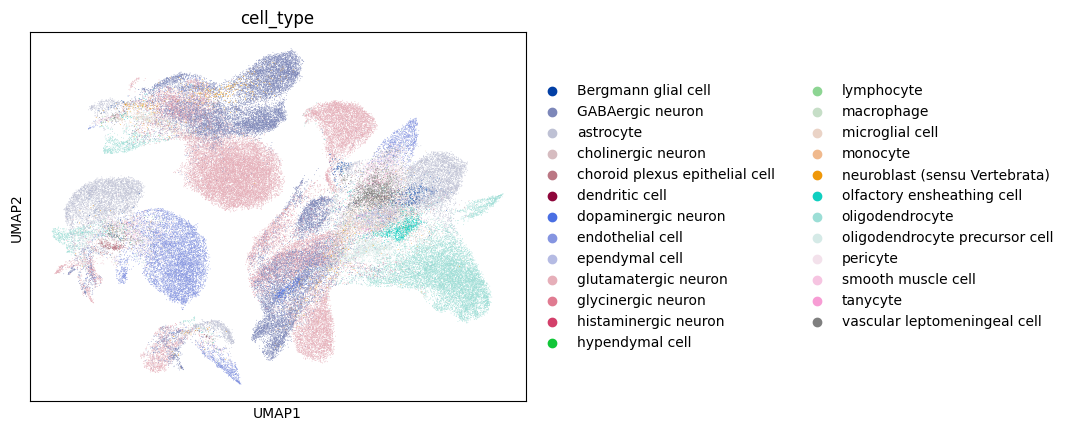

In [50]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.2.3 Logistic regression

In [51]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.81
Test F1 Score: 0.78
Train Accuracy: 0.81
Train F1 Score: 0.78


{'test_accuracy': 0.8105,
 'test_f1': 0.7835988493642977,
 'train_accuracy': 0.811125,
 'train_f1': 0.7849392379749927}

### 5.2.4 KNN

In [52]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.89
Test F1 Score: 0.89
Train Accuracy: 0.92
Train F1 Score: 0.92


{'test_accuracy': 0.89375,
 'test_f1': 0.8888156755122938,
 'train_accuracy': 0.9234,
 'train_f1': 0.9201974729164288}

### 5.2.5 nmi&ari

In [53]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.38709246658094565
ARI (Adjusted Rand Index): 0.1612334554317972


{'nmi': 0.38709246658094565, 'ari': 0.1612334554317972}

## 5.3 Cell Type weighted_average

In [54]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False

params['mask']['context_mask_size'] = 457
params['mask']['target_mask_size'] = 10
params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9

params['meta']['pred_emb_dim'] = 768
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['epochs'] = 40


adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 40 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:04, 16.69it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
400it [01:04,  6.17it/s]
100it [00:17,  5.75it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_457_num_epochs_40_just_cell_total/extracted_features/cell_embedding_weighted_average.h5ad


### 5.3.1 Feature Analysis

In [68]:
adata = ad.read_h5ad('logs/merfish_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_457_num_epochs_40_just_cell_total/extracted_features/cell_embedding_weighted_average.h5ad')

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000002  0.9750538  0.984086   ... 0.9418602  0.9724439  0.9640368 ]
 [0.9750538  0.99999976 0.98234916 ... 0.9701638  0.9919616  0.9867574 ]
 [0.984086   0.98234916 0.99999994 ... 0.95272756 0.9796791  0.972203  ]
 ...
 [0.9418602  0.9701638  0.95272756 ... 0.9999997  0.9798795  0.9890797 ]
 [0.9724439  0.9919616  0.9796791  ... 0.9798795  1.         0.9919928 ]
 [0.9640368  0.9867574  0.972203   ... 0.9890797  0.9919928  1.0000001 ]]


array([[ 0.5079148 ,  0.125876  ,  1.2788657 , ...,  0.2113362 ,
         0.05949916, -0.7763036 ],
       [ 0.6205504 , -0.0496264 ,  1.1924701 , ...,  0.27789134,
         0.32206538, -0.77026975],
       [ 0.5748722 ,  0.15375212,  1.334892  , ...,  0.15172365,
         0.16650674, -0.7488533 ],
       ...,
       [ 0.48264852,  0.09658301,  1.3550613 , ...,  0.32385987,
         0.17650646, -0.83269334],
       [ 0.59703165, -0.01176757,  1.156394  , ...,  0.30673993,
         0.26824054, -0.81352544],
       [ 0.26278964,  0.05744298,  1.3383512 , ...,  0.15119952,
         0.12017807, -0.8472245 ]], dtype=float32)

### 5.3.2 Umap

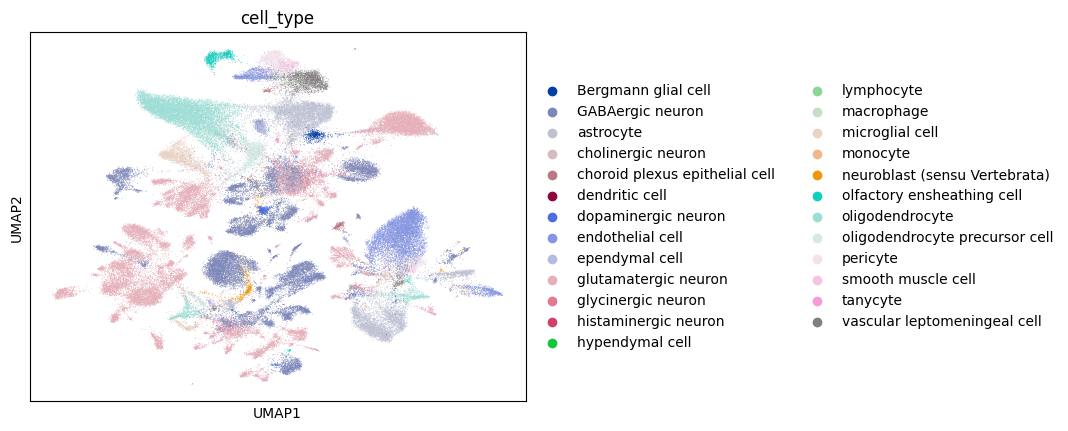

In [56]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.3.3 Logistic regression

In [57]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.92
Test F1 Score: 0.92
Train Accuracy: 0.92
Train F1 Score: 0.92


{'test_accuracy': 0.92215,
 'test_f1': 0.915038138155501,
 'train_accuracy': 0.9242875,
 'train_f1': 0.9181146665040023}

### 5.3.4 KNN

In [58]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.93
Test F1 Score: 0.93
Train Accuracy: 0.95
Train F1 Score: 0.95


{'test_accuracy': 0.9336,
 'test_f1': 0.9321045520061947,
 'train_accuracy': 0.9472,
 'train_f1': 0.9461208624538041}

### 5.3.5 nmi&ari

In [59]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.46385984107418504
ARI (Adjusted Rand Index): 0.21648932002181973


{'nmi': 0.46385984107418504, 'ari': 0.21648932002181973}